# Machine Learning Assignment 4: Car Price Prediction

The assignment asks us to predict car prices using the available car features, compare five regression algorithms, identify important variables, and tune the best model.

**Dataset:** `CarPrice_Assignment.csv`  
**Target column:** `price`  
**Models:** Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Support Vector Regressor (SVR).


## 1. Import libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the dataset

In [3]:
df = pd.read_csv("CarPrice_Assignment.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn data types:")
print(df.dtypes)
print("\\nMissing values per column:")
print(df.isnull().sum())
print("\\nDuplicate rows:",df.duplicated().sum())

Dataset shape: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


\nColumn data types:
car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object
\nMissing values per column:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase 

In [4]:

data = df.copy()
data = data.drop_duplicates()
data["manufacturer"]=data["CarName"].astype(str).str.split().str[0].str.lower()

data = data.drop(columns=["car_ID", "CarName"], errors="ignore")
data["price"]=pd.to_numeric(data["price"], errors="coerce")
data=data.dropna(subset=["price"])

print("Shape after basic preprocessing:", data.shape)
print("Missing values remaining:", int(data.isnull().sum().sum()))
display(data.head())

Shape after basic preprocessing: (205, 25)
Missing values remaining: 0


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,manufacturer
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


## 3. Explore the target variable

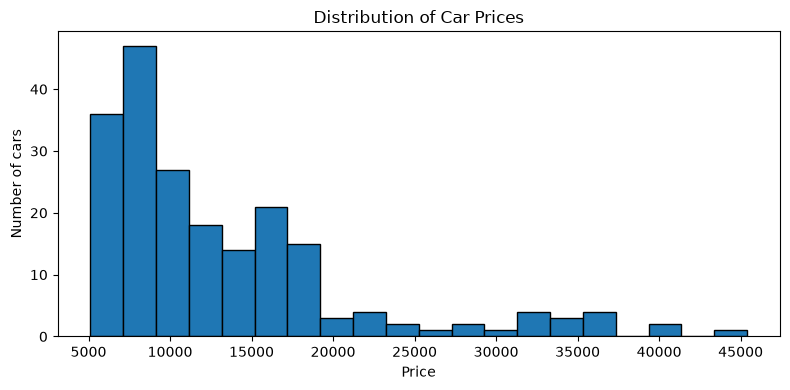

,correlation_with_price
price,1.000000
enginesize,0.874145
curbweight,0.835305
horsepower,0.808139
carwidth,0.759325
carlength,0.682920
wheelbase,0.577816
boreratio,0.553173
carheight,0.119336
stroke,0.079443


In [5]:
plt.figure(figsize=(8, 4))
plt.hist(data["price"], bins=20, edgecolor="black")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

numeric_data=data.select_dtypes(include=np.number)
correlations=numeric_data.corr(numeric_only=True)["price"].sort_values(ascending=False)
display(correlations.to_frame("correlation_with_price"))

## 4. Split features and target; prepare preprocessing

In [7]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

RANDOM_STATE = 42

In [8]:
X=data.drop(columns=["price"])
y=data["price"]

numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer=Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor=ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 164
Testing rows: 41
Numeric features: 14
Categorical features: 10


## 5. Train five regression models

In [9]:
models={
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Support Vector Regressor": SVR()
}

results=[]
fitted_models={}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "R-squared": r2_score(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions)
    })
    fitted_models[model_name] = pipeline

results_df=pd.DataFrame(results).sort_values("R-squared", ascending=False).reset_index(drop=True)
display(results_df.round(3))

,Model,R-squared,MSE,MAE
0,Random Forest Regressor,0.958,3.334668e+06,1287.185
1,Gradient Boosting Regressor,0.928,5.671210e+06,1690.949
2,Decision Tree Regressor,0.914,6.820817e+06,1704.142
3,Linear Regression,0.900,7.906808e+06,1835.328
4,Support Vector Regressor,-0.100,8.682185e+07,5695.274


### Model comparison and best model

Best model before tuning (by test R-squared): Random Forest Regressor


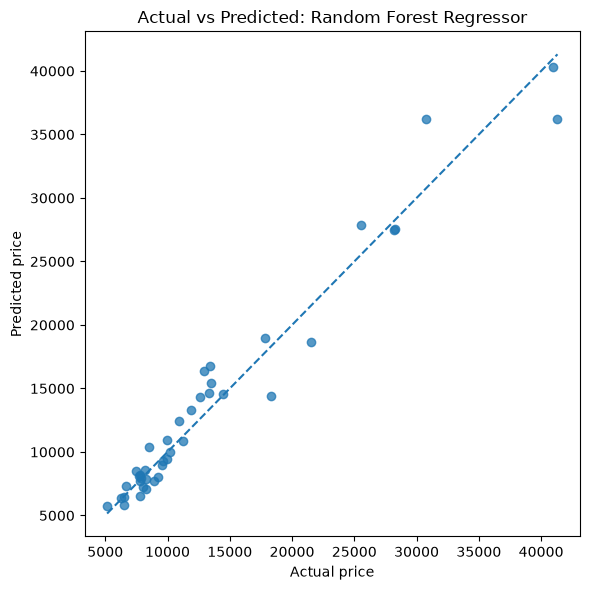

In [10]:
best_model_name=results_df.loc[0, "Model"]
best_model=fitted_models[best_model_name]

print("Best model before tuning (by test R-squared):", best_model_name)
best_predictions=best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.75)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()

## 6. Feature importance 

,Feature,Importance
6,numeric__enginesize,0.5754
5,numeric__curbweight,0.2717
13,numeric__highwaympg,0.0446
10,numeric__horsepower,0.0267
3,numeric__carwidth,0.0127
2,numeric__carlength,0.0086
53,categorical__manufacturer_bmw,0.0072
1,numeric__wheelbase,0.0072
12,numeric__citympg,0.0067
11,numeric__peakrpm,0.0054


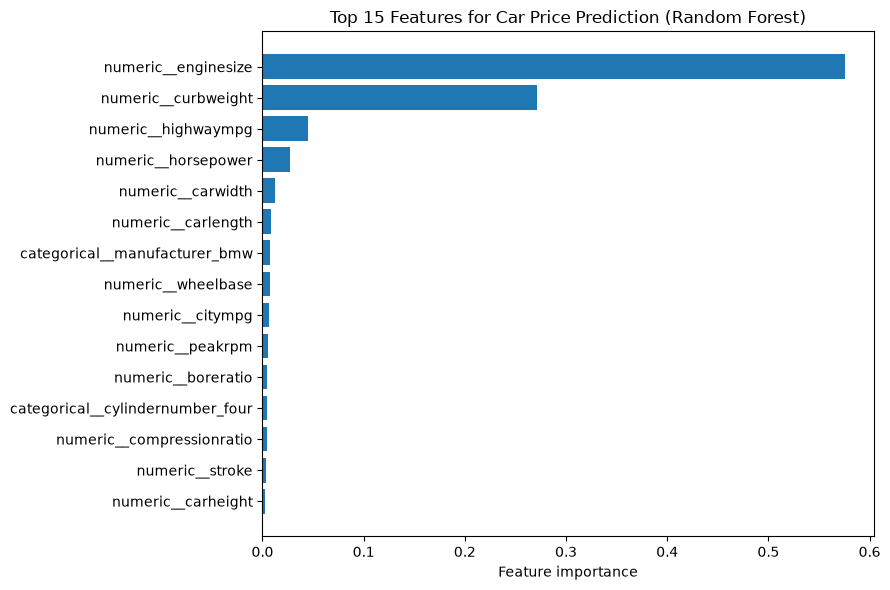

In [11]:
rf_pipeline=fitted_models["Random Forest Regressor"]
fitted_preprocessor=rf_pipeline.named_steps["preprocessor"]
rf_model=rf_pipeline.named_steps["model"]

feature_names=fitted_preprocessor.get_feature_names_out()
importances=rf_model.feature_importances_

importance_df=pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features=importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.title("Top 15 Features for Car Price Prediction (Random Forest)")
plt.tight_layout()
plt.show()

## 7. Hyperparameter tuning

In [12]:
parameter_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False]
    },
    "Decision Tree Regressor": {
        "model__max_depth": [None, 3, 5, 8, 12],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "Random Forest Regressor": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 8, 12],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    },
    "Gradient Boosting Regressor": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3]
    },
    "Support Vector Regressor": {
        "model__C": [1, 10, 100],
        "model__epsilon": [0.1, 0.2],
        "model__kernel": ["rbf"]
    }
}

tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grids[best_model_name],
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

tuned_model = grid_search.best_estimator_
print("Model selected for tuning:", best_model_name)
print("Best parameters:", grid_search.best_params_)
print("Best mean cross-validation R-squared:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Model selected for tuning: Random Forest Regressor
Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best mean cross-validation R-squared: 0.8902


## 8. Evaluate tuned model on the test set

In [13]:
tuned_predictions = tuned_model.predict(X_test)

before_tuning = {
    "Stage": "Before tuning",
    "R-squared": r2_score(y_test, best_predictions),
    "MSE": mean_squared_error(y_test, best_predictions),
    "MAE": mean_absolute_error(y_test, best_predictions)
}
after_tuning = {
    "Stage": "After tuning",
    "R-squared": r2_score(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "MAE": mean_absolute_error(y_test, tuned_predictions)
}

tuning_comparison = pd.DataFrame([before_tuning, after_tuning])
display(tuning_comparison.round(3))

if after_tuning["R-squared"] > before_tuning["R-squared"]:
    print("Conclusion: Test R-squared increased after tuning.")
elif after_tuning["R-squared"] < before_tuning["R-squared"]:
    print("Conclusion: Test R-squared decreased after tuning.")
else:
    print("Conclusion: Test R-squared stayed the same after tuning.")

,Stage,R-squared,MSE,MAE
0,Before tuning,0.958,3334667.861,1287.185
1,After tuning,0.958,3351042.150,1286.875


Conclusion: Test R-squared decreased after tuning.


## 9. Final conclusion

In [14]:
print("FINAL SUMMARY")
print("-------------")
print(f"Best initial model: {best_model_name}")
print(f"Before tuning: R²={before_tuning['R-squared']:.3f}, "
      f"MSE={before_tuning['MSE']:.2f}, MAE={before_tuning['MAE']:.2f}")
print(f"After tuning:  R²={after_tuning['R-squared']:.3f}, "
      f"MSE={after_tuning['MSE']:.2f}, MAE={after_tuning['MAE']:.2f}")
print("Top 5 Random Forest features:")
for feature in importance_df.head(5)["Feature"]:
    print("-", feature)

print("\\nInterpretation:")
print("- Higher R-squared means the model explains more variation in car prices.")
print("- Lower MSE and MAE mean smaller prediction errors.")
print("- Feature importance identifies useful predictors, not causal effects.")
print("- Report the scores produced by this notebook; results can vary if the split or settings change.")

FINAL SUMMARY
-------------
Best initial model: Random Forest Regressor
Before tuning: R²=0.958, MSE=3334667.86, MAE=1287.18
After tuning:  R²=0.958, MSE=3351042.15, MAE=1286.88
Top 5 Random Forest features:
- numeric__enginesize
- numeric__curbweight
- numeric__highwaympg
- numeric__horsepower
- numeric__carwidth
\nInterpretation:
- Higher R-squared means the model explains more variation in car prices.
- Lower MSE and MAE mean smaller prediction errors.
- Feature importance identifies useful predictors, not causal effects.
- Report the scores produced by this notebook; results can vary if the split or settings change.
